In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import scipy
import squarify

In [2]:
df = pd.read_csv("data/heart.csv")
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


# Heart Disease Analysis

## 1. Dataset Selection

**1. Dataset name**
Heart Failure Prediction Dataset (heart.csv)

**2. Source**
Kaggle: https://www.kaggle.com/datasets/endofnight17j03/heart-failure-prediction-dataset?select=heart.csv

**3. Why I chose it**
- Heart failure is an interesting and important topic.
- I want to see which gender has higher cholesterol, and how age affects it.
- I go to the gym, so I want to see whether exercise-related measures link to heart disease.
- The dataset has 918 patients with a mix of numeric and categorical columns, so there is enough data for meaningful analysis and cleaning.

**4. Questions I am aiming to answer**
1. Which gender has more heart disease?
2. Which age group shows the most signs of heart disease?
3. Do patients who get chest pain during exercise have more heart disease?
4. Do patients with a higher maximum heart rate have less heart disease?
5. Which type of chest pain is most linked to heart disease?
6. Which gender has higher cholesterol, and does it change with age or link to heart disease?

## 2. Initial Data Exploration

In [3]:
df.shape # number of rows and coloums

(918, 12)

In [4]:
df.columns # coloumn names

Index(['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS',
       'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope',
       'HeartDisease'],
      dtype='str')

In [5]:
df.dtypes # data types

Age                 int64
Sex                   str
ChestPainType         str
RestingBP           int64
Cholesterol         int64
FastingBS           int64
RestingECG            str
MaxHR               int64
ExerciseAngina        str
Oldpeak           float64
ST_Slope              str
HeartDisease        int64
dtype: object

In [6]:
df.head() # first few rows

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [7]:
df.describe() # summary of table

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


In [8]:
pd.isnull(df).sum() #fixingmissing values

Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

In [9]:
df.duplicated().sum() # any duplciates

np.int64(0)

In [10]:
df.groupby("HeartDisease").size() # number of ppl with heart disease

HeartDisease
0    410
1    508
dtype: int64

In [11]:
df.groupby("Sex").size() #number of patients female or male

Sex
F    193
M    725
dtype: int64

In [12]:
df.groupby("ChestPainType").size() # how many ppl have chest pain

ChestPainType
ASY    496
ATA    173
NAP    203
TA      46
dtype: int64

### Exploration findings
- The dataset has 918 rows and 12 columns.
- There are 5 numeric columns plus `FastingBS` and `HeartDisease`, which are coded 0/1, and 5 text columns (`Sex`, `ChestPainType`, `RestingECG`, `ExerciseAngina`, `ST_Slope`).
- There are no missing (null) values and no duplicate rows.
- `HeartDisease` is fairly balanced: 508 patients with heart disease and 410 without.
- `Cholesterol` has a minimum of 0 and `RestingBP` has a minimum of 0. Neither is possible for a living patient, so these are hidden missing values to clean.
- `Oldpeak` has a minimum of -2.6, so some values are negative and need checking.
- The data is mostly male (725 males vs 193 females), which may affect gender comparisons.

## 3. Data Cleaning

In [13]:
df_before = df.copy() #keeps copy of data

In [14]:
df.duplicated().sum() #checking for duplicates

np.int64(0)

In [15]:
df.drop_duplicates(inplace=True) #removes dups
df.shape

(918, 12)

In [16]:
print("Cholesterol = 0:", (df["Cholesterol"] == 0).sum()) # counts missing vaules 
print("RestingBP = 0:", (df["RestingBP"] == 0).sum())
print("Oldpeak below 0:", (df["Oldpeak"] < 0).sum())

Cholesterol = 0: 172
RestingBP = 0: 1
Oldpeak below 0: 13


In [17]:
df[df["RestingBP"] == 0] # finding missing value

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
449,55,M,NAP,0,0,0,Normal,155,N,1.5,Flat,1


In [18]:
df = df[df["RestingBP"] > 0] #dropping the values
df = df.reset_index(drop=True)
df.shape

(917, 12)

In [19]:
df.loc[df["Cholesterol"] == 0, "Cholesterol"] = np.nan # turning zero into Nan
pd.isnull(df).sum()

Age                 0
Sex                 0
ChestPainType       0
RestingBP           0
Cholesterol       171
FastingBS           0
RestingECG          0
MaxHR               0
ExerciseAngina      0
Oldpeak             0
ST_Slope            0
HeartDisease        0
dtype: int64

In [20]:
df["CholesterolMissing"] = pd.isnull(df["Cholesterol"])
df["Cholesterol"] = df["Cholesterol"].fillna(df["Cholesterol"].median())
pd.isnull(df).sum()  #filling missing value with median

Age                   0
Sex                   0
ChestPainType         0
RestingBP             0
Cholesterol           0
FastingBS             0
RestingECG            0
MaxHR                 0
ExerciseAngina        0
Oldpeak               0
ST_Slope              0
HeartDisease          0
CholesterolMissing    0
dtype: int64

In [21]:
df["Cholesterol"] = df["Cholesterol"].astype(int) #changing the data type
df.dtypes

Age                     int64
Sex                       str
ChestPainType             str
RestingBP               int64
Cholesterol             int64
FastingBS               int64
RestingECG                str
MaxHR                   int64
ExerciseAngina            str
Oldpeak               float64
ST_Slope                  str
HeartDisease            int64
CholesterolMissing       bool
dtype: object

In [22]:
df["HeartDiseaseLabel"] = df["HeartDisease"].map({0: "No Heart Disease", 1: "Heart Disease"})
df["FastingBSLabel"] = df["FastingBS"].map({0: "Normal", 1: "High"})
df.head() # chaning the coloumn name since 0 and 1 not readable

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease,CholesterolMissing,HeartDiseaseLabel,FastingBSLabel
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0,False,No Heart Disease,Normal
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1,False,Heart Disease,Normal
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0,False,No Heart Disease,Normal
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1,False,Heart Disease,Normal
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0,False,No Heart Disease,Normal


In [23]:
df.loc[df["Age"] < 40, "AgeGroup"] = "Under 40"  #age grouping for analysis
df.loc[(df["Age"] >= 40) & (df["Age"] < 50), "AgeGroup"] = "40-49"
df.loc[(df["Age"] >= 50) & (df["Age"] < 60), "AgeGroup"] = "50-59"
df.loc[df["Age"] >= 60, "AgeGroup"] = "60+"
df.groupby("AgeGroup").size()

AgeGroup
40-49       211
50-59       373
60+         253
Under 40     80
dtype: int64

In [24]:
print(df.shape)
print(pd.isnull(df).sum().sum())
df.describe()

(917, 16)
0


,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,917.000000,917.000000,917.000000,917.000000,917.000000,917.000000,917.000000
mean,53.509269,132.540894,243.211559,0.233370,136.789531,0.886696,0.552890
std,9.437636,17.999749,53.430044,0.423206,25.467129,1.066960,0.497466
min,28.000000,80.000000,85.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,214.000000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,237.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


In [25]:
df.to_csv("data/heart_clean.csv", index=False) # saving work for today

### Cleaning decisions
- **Duplicates:** Found None, so no rows were removed.
- **Missing values:** There were no nulls, but 172 `Cholesterol` values and 1 `RestingBP` value were 0, which is not possible for a living patient. These were hidden missing values.
- **RestingBP = 0:** Only 1 row, so I dropped it (917 rows remain).
- **Cholesterol = 0:** 171 rows were left after dropping the BP row. That is about 19% of the data, too many to drop. I turned them into NaN and filled them with the median (237), which is not pulled around by extreme values. I added a `CholesterolMissing` column so these rows can still be identified later.
- **Oldpeak < 0:** 13 rows have a negative value. I kept them, because negative ST depression can occur in real patients.
- **Data types:** `Cholesterol` became a decimal when NaN was added, so I converted it back to an integer.
- **New columns:** Readable labels for `HeartDisease` and `FastingBS`, and an `AgeGroup` column for the age analysis.
- **Limitation:** Filling 19% of cholesterol with one value reduces its natural variation, so cholesterol results need to be read with care.

## 4. Data Analysis

### Q1: Which gender has more heart disease?

In [26]:
gender_rate = df.groupby("Sex")["HeartDisease"].mean() * 100
gender_rate  # I split the data then checked heartdisease coloumn

Sex
F    25.906736
M    63.121547
Name: HeartDisease, dtype: float64

In [27]:
pd.crosstab(df["Sex"], df["HeartDiseaseLabel"]) # table building

HeartDiseaseLabel,Heart Disease,No Heart Disease
Sex,,
F,50,143
M,457,267


### Q2: Which age group shows the most signs of heart disease?

In [28]:
age_rate = df.groupby("AgeGroup")["HeartDisease"].mean() * 100
age_rate = age_rate.loc[["Under 40", "40-49", "50-59", "60+"]]
age_rate # reordering the coloumns

AgeGroup
Under 40    32.500000
40-49       40.284360
50-59       56.568365
60+         73.122530
Name: HeartDisease, dtype: float64

### Q3: Do patients who get chest pain during exercise have more heart disease?

In [29]:
angina_rate = df.groupby("ExerciseAngina")["HeartDisease"].mean() * 100
angina_rate # split tbale to see percentagne

ExerciseAngina
N    34.981685
Y    85.175202
Name: HeartDisease, dtype: float64

In [30]:
pd.crosstab(df["ExerciseAngina"], df["HeartDiseaseLabel"])

HeartDiseaseLabel,Heart Disease,No Heart Disease
ExerciseAngina,,
N,191,355
Y,316,55


### Q4: Do patients with a higher maximum heart rate have less heart disease?

In [31]:
maxhr_avg = df.groupby("HeartDiseaseLabel")["MaxHR"].mean()
maxhr_avg # split

HeartDiseaseLabel
Heart Disease       127.601578
No Heart Disease    148.151220
Name: MaxHR, dtype: float64

In [32]:
maxhr_by_age = df.groupby(["AgeGroup", "HeartDiseaseLabel"])["MaxHR"].mean().unstack()
maxhr_by_age #group by

HeartDiseaseLabel,Heart Disease,No Heart Disease
AgeGroup,,
40-49,134.811765,153.150794
50-59,126.767773,144.555556
60+,122.729730,135.823529
Under 40,145.461538,162.796296


### Q5: Which type of chest pain is most linked to heart disease?

In [33]:
chest_rate = df.groupby("ChestPainType")["HeartDisease"].mean() * 100
chest_rate = chest_rate.sort_values(ascending=False)
chest_rate # ranking results highest to lowest

ChestPainType
ASY    79.032258
TA     43.478261
NAP    35.148515
ATA    13.872832
Name: HeartDisease, dtype: float64

In [34]:
df.groupby("ChestPainType").size() # counter

ChestPainType
ASY    496
ATA    173
NAP    202
TA      46
dtype: int64

### Q6: Which gender has higher cholesterol, and does it change with age or link to heart disease?

In [35]:
real_chol = df[df["CholesterolMissing"] == False]
real_chol.groupby("Sex")["Cholesterol"].mean() #avg chol lvl for each gender

Sex
F    255.774725
M    241.040780
Name: Cholesterol, dtype: float64

In [36]:
chol_age_sex = real_chol.groupby(["AgeGroup", "Sex"])["Cholesterol"].mean().unstack()
chol_age_sex = chol_age_sex.loc[["Under 40", "40-49", "50-59", "60+"]]
chol_age_sex #avg choleotest per group and then adding m or f

Sex,F,M
AgeGroup,,
Under 40,206.823529,240.792453
40-49,234.230769,244.517986
50-59,272.314286,238.849785
60+,274.255814,241.330935


In [37]:
real_chol.groupby("HeartDiseaseLabel")["Cholesterol"].mean() # mean

HeartDiseaseLabel
Heart Disease       251.061798
No Heart Disease    238.769231
Name: Cholesterol, dtype: float64

In [38]:
df.groupby("CholesterolMissing")["HeartDisease"].mean() * 100 #split data

CholesterolMissing
False    47.721180
True     88.304094
Name: HeartDisease, dtype: float64

### Analysis findings
- **Q1:** Males have a much higher heart disease rate (63.1%) than females (25.9%). Of 193 females, 50 have heart disease, and of 724 males, 457 do. The dataset has far fewer females, so this is worth noting.
- **Q2:** Heart disease rises with age: 32.5% under 40, 40.3% for 40-49, 56.6% for 50-59, and 73.1% for 60+. The risk more than doubles from the youngest to the oldest group.
- **Q3:** 85.2% of patients with chest pain during exercise have heart disease, against 35.0% of those without it.
- **Q4:** Patients with heart disease have a lower average maximum heart rate (127.6) than those without (148.2). This holds in every age group, so it is not just caused by age.
- **Q5:** Asymptomatic chest pain (ASY) has the highest rate at 79.0%, and ATA the lowest at 13.9%. Patients with no chest pain symptoms are the highest risk, which is unexpected.
- **Q6:** Females have higher average cholesterol (255.8) than males (241.0), despite having less heart disease. Female cholesterol rises with age. The difference in cholesterol between patients with and without heart disease is small (251.1 vs 238.8).
- **Unexpected result:** Patients whose cholesterol was recorded as 0 had heart disease 88.3% of the time, compared with 47.7% for the rest. The missing values are not random.
- **Limitation:** The dataset has no gym attendance column.

## 5. Visualisations

### Overview: Which measurements separate patients with and without heart disease?

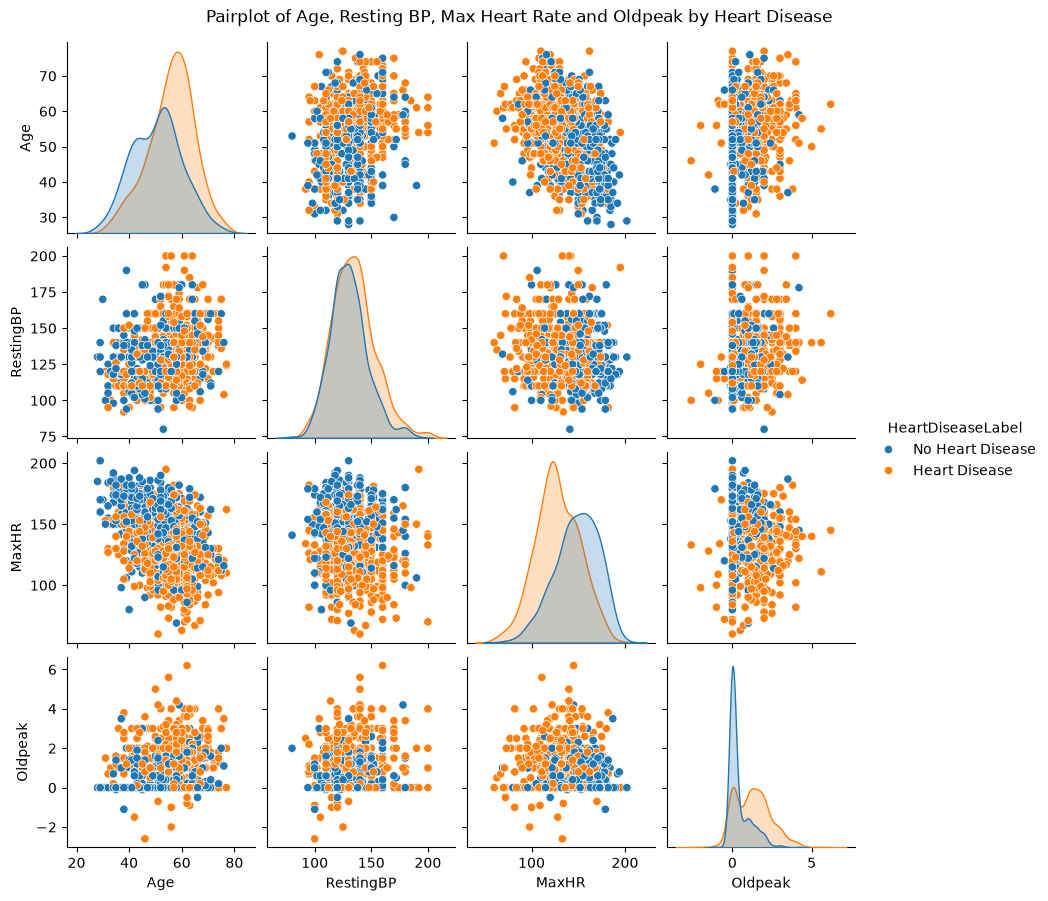

In [39]:
g = sns.pairplot(df, vars=["Age", "RestingBP", "MaxHR", "Oldpeak"], hue="HeartDiseaseLabel", height=2.2)  # 4 columns, 16 charts
g.fig.suptitle("Pairplot of Age, Resting BP, Max Heart Rate and Oldpeak by Heart Disease", y=1.02)  # one title for grid
plt.show()

**Overview:** Patients with heart disease (orange) tend to be older, have a lower maximum heart rate and a higher Oldpeak. Those three split the two groups best.


**Recommendation:** Heart rate, age and Oldpeak should be the first measurements checked when assessing risk.

### Q1: Which gender has more heart disease?

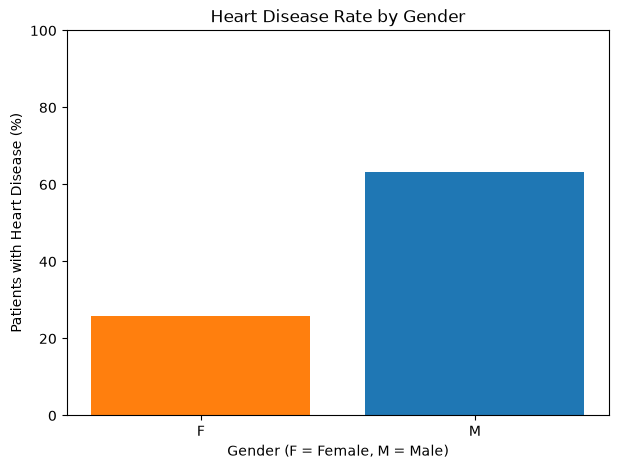

In [40]:
plt.figure(figsize=(7, 5))  # chart size
plt.bar(gender_rate.index, gender_rate.values, color=["tab:orange", "tab:blue"])  # one bar per gender
plt.title("Heart Disease Rate by Gender")
plt.xlabel("Gender (F = Female, M = Male)")
plt.ylabel("Patients with Heart Disease (%)")
plt.ylim(0, 100)  # percent so max 100
plt.show()

**Q1:** Men have a lot more heart disease than women (63.1% vs 25.9%).

**Recommendation:** Men should be prioritised for screening. There are far fewer women in the data, so the gap shouldn’t be treated as final.

### Q2: Which age group shows the most signs of heart disease?

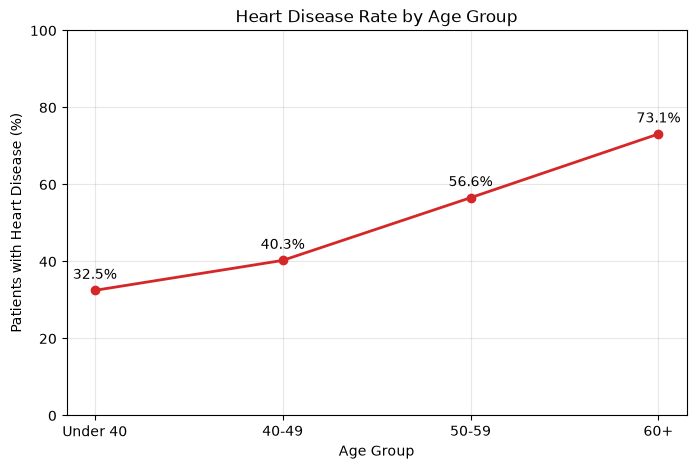

In [41]:
plt.figure(figsize=(8, 5))  # chart size
plt.plot(age_rate.index, age_rate.values, marker="o", linewidth=2, color="tab:red")  # line shows the trend
for x, y in zip(age_rate.index, age_rate.values):  # loop through each point
    plt.text(x, y + 3, f"{y:.1f}%", ha="center")  # % label above dot
plt.title("Heart Disease Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Patients with Heart Disease (%)")
plt.ylim(0, 100)
plt.grid(alpha=0.3)  # light grid lines
plt.show()

**Q2:** The line only goes up. Heart disease goes from 32.5% in the under 40s to 73.1% in the 60+ group.

 **Recommendation:** Screening should focus on patients aged 50 and over, where more than half have heart disease.

### Q3: Do patients who get chest pain during exercise have more heart disease?

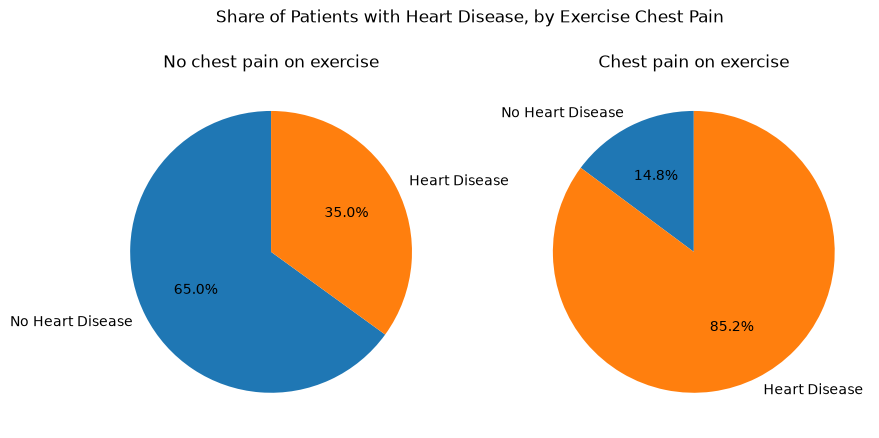

In [42]:
counts = pd.crosstab(df["ExerciseAngina"], df["HeartDiseaseLabel"])  # patient counts per group
order = ["No Heart Disease", "Heart Disease"]  # same colours both pies

fig, axes = plt.subplots(1, 2, figsize=(10, 5))  # two pies side by side
for ax, key, name in zip(axes, ["N", "Y"], ["No chest pain on exercise", "Chest pain on exercise"]):  # one pie each
    ax.pie(counts.loc[key, order], labels=order, autopct="%1.1f%%",
           startangle=90, colors=["tab:blue", "tab:orange"])  # % shown on slices
    ax.set_title(name)
fig.suptitle("Share of Patients with Heart Disease, by Exercise Chest Pain")
plt.show()

**Q3:** 85.2% of patients with chest pain on exercise have heart disease, against 35.0% of those without it. I can conclude that there is a big gap.

**Recommendation:** Chest pain during exercise should be treated as a priority warning sign. It shows a link, not a cause.

### Q4: Do patients with a higher maximum heart rate have less heart disease?

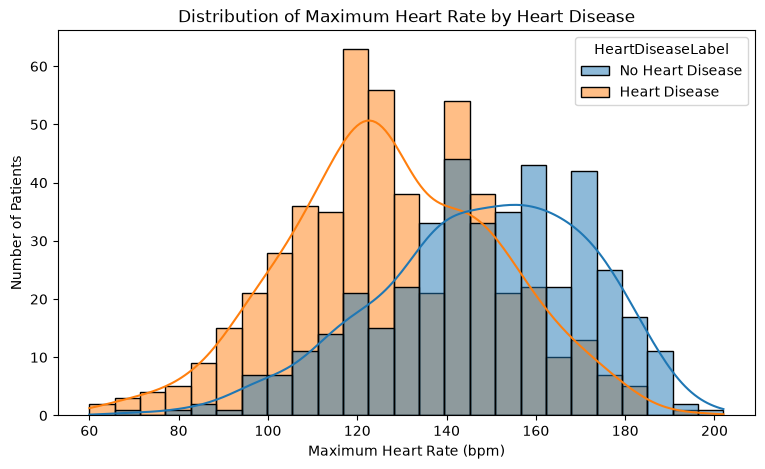

In [51]:
plt.figure(figsize=(9, 5)) #Max heart rate distribution
sns.histplot(data=df, x="MaxHR", hue="HeartDiseaseLabel", bins=25, kde=True)
plt.title("Distribution of Maximum Heart Rate by Heart Disease")
plt.xlabel("Maximum Heart Rate (bpm)")
plt.ylabel("Number of Patients")
plt.show()

**Q4:** The heart disease group peaks at a lower heart rate (127.6 bpm on average vs 148.2).


**Recommendation:** A low maximum heart rate should prompt a closer look, especially alongside other risk factors.

### Q4 (continued): Is the whole group lower, or just the average?

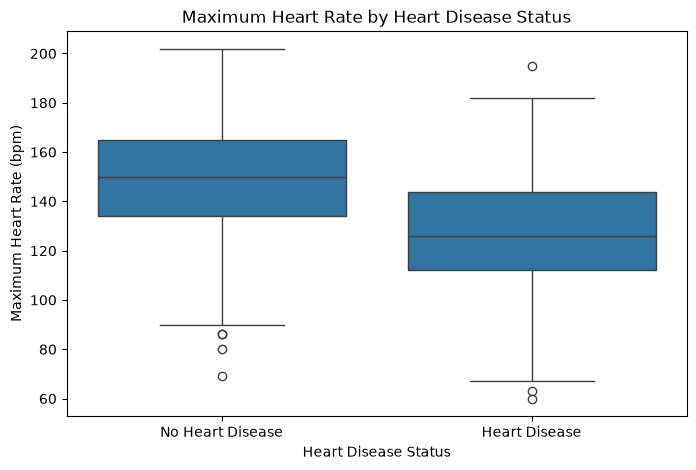

In [44]:
plt.figure(figsize=(8, 5))  # chart size
sns.boxplot(data=df, x="HeartDiseaseLabel", y="MaxHR")  # box is middle 50%
plt.title("Maximum Heart Rate by Heart Disease Status")
plt.xlabel("Heart Disease Status")
plt.ylabel("Maximum Heart Rate (bpm)")
plt.show()

**Q4 (continued):** The whole box for the heart disease group sits lower, not just the average. Low heart rates are normal for this group.

**Recommendation:** Heart rate should be judged against others of the same age, because the gap holds in every age group.

### Q5: Which type of chest pain is most linked to heart disease?

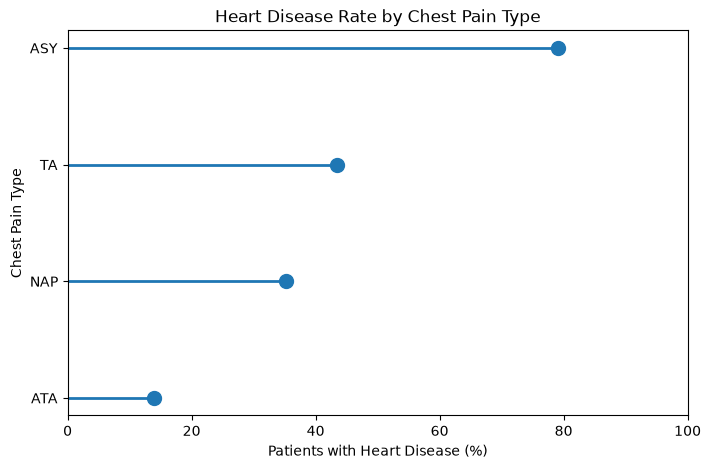

In [45]:
plt.figure(figsize=(8, 5))  # chart size
plt.hlines(y=chest_rate.index, xmin=0, xmax=chest_rate.values, color="tab:blue", linewidth=2)  # the sticks
plt.plot(chest_rate.values, chest_rate.index, "o", color="tab:blue", markersize=10)  # the dots
plt.title("Heart Disease Rate by Chest Pain Type")
plt.xlabel("Patients with Heart Disease (%)")
plt.ylabel("Chest Pain Type")
plt.xlim(0, 100)
plt.gca().invert_yaxis()  # highest rate on top
plt.show()

**Q5:** ASY (no chest pain symptoms) is the highest at 79.0% and ATA is the lowest at 13.9%.

**Recommendation:** Patients with no chest pain symptoms shouldn’t be treated as low risk, since 79% of them had heart disease.

### Q6: Which gender has higher cholesterol, and does it change with age or link to heart disease?

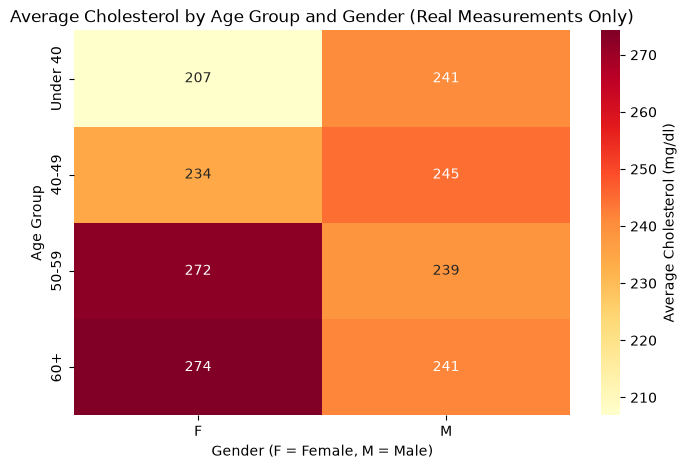

In [46]:
plt.figure(figsize=(8, 5))  # chart size
sns.heatmap(chol_age_sex, annot=True, fmt=".0f", cmap="YlOrRd",
            cbar_kws={"label": "Average Cholesterol (mg/dl)"})  # numbers inside boxes
plt.title("Average Cholesterol by Age Group and Gender (Real Measurements Only)")
plt.xlabel("Gender (F = Female, M = Male)")
plt.ylabel("Age Group")
plt.show()

**Q6:** Women's cholesterol goes up with age and passes men's from 50. Men stay flat at around 240. Overall women average 255.8 vs 241.0 for men, even though women have less heart disease. Cholesterol is only weakly linked to heart disease (251.1 with it, 238.8 without).

**Conclusion:** Cholesterol shouldn’t be used as the only risk marker, because the gap between the two groups was small.

### Data check: Did cleaning remove the impossible zero cholesterol values?

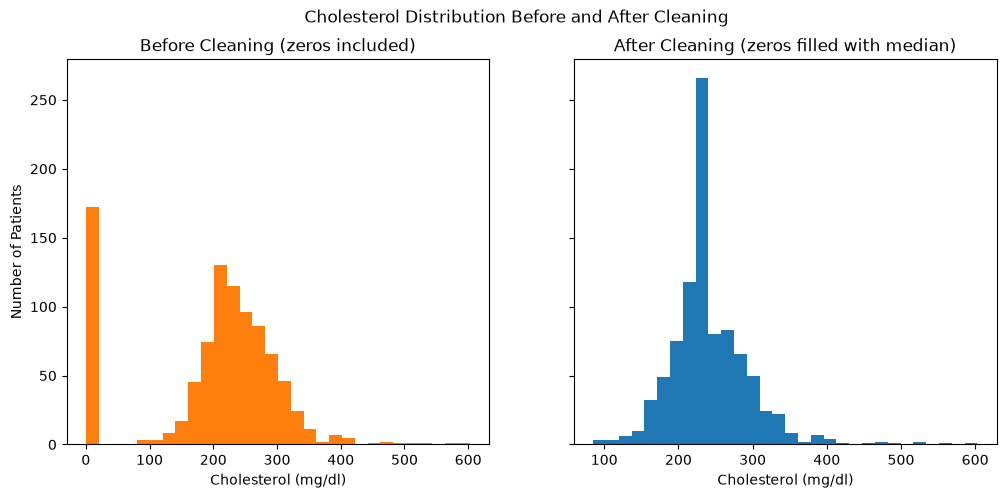

In [52]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True) #Cholesterol before and after cleaning
axes[0].hist(df_before["Cholesterol"], bins=30, color="tab:orange")
axes[0].set_title("Before Cleaning (zeros included)")
axes[0].set_xlabel("Cholesterol (mg/dl)")
axes[0].set_ylabel("Number of Patients")
axes[1].hist(df["Cholesterol"], bins=30, color="tab:blue")
axes[1].set_title("After Cleaning (zeros filled with median)")
axes[1].set_xlabel("Cholesterol (mg/dl)")
fig.suptitle("Cholesterol Distribution Before and After Cleaning")
plt.show()

**Data check:** Before cleaning, a big group of patients sits at 0, which can't be real cholesterol. After cleaning the zeros are gone, but a lot of values now sit at the median, so the middle looks narrower. I flagged those rows in `CholesterolMissing` so I can still tell them apart.

**Conclusion:** Missing cholesterol should be recorded as blank rather than 0, so it can’t be mistaken for a real reading.

### 6. Final Summary


### Key findings
- **Gender:** Men had a much higher heart disease rate (63.1%) than women (25.9%).
- **Age:** The rate rose with age, from 32.5% for under 40s to 73.1% for the 60+ group.
- **Exercise chest pain:** 85.2% of patients who got chest pain during exercise had heart disease, against 35.0% of those who did not. This was the closest measure I had to my gym question.
- **Maximum heart rate:** Patients with heart disease reached a lower maximum heart rate (127.6 bpm on average vs 148.2 bpm).
- **Chest pain type:** Asymptomatic chest pain (ASY) was the most linked type at 79.0%, and ATA was the lowest at 13.9%.
- **Cholesterol:** Women had higher average cholesterol (255.8) than men (241.0). Cholesterol was only weakly linked to heart disease (251.1 with it, 238.8 without).

### Trends
- Heart disease risk went up at every step in age.
- Maximum heart rate was lower for patients with heart disease in every age group (for example 145.5 vs 162.8 bpm under 40, and 122.7 vs 135.8 bpm for 60+). Age alone does not explain the gap.
- Women's cholesterol rose with age and overtook men's from 50, while men's stayed fairly flat at around 240.
- The pairplot showed that heart disease goes with older age, a low
- er maximum heart rate and a higher Oldpeak (1.27 on average vs 0.41 without heart disease).

### Unexpected results
- Patients with no chest pain symptoms (ASY) had the most heart disease.Having no chest pain did not mean low risk.
- Zero cholesterol values were not random. The 171 patients with a recorded cholesterol of 0 had heart disease 88.3% of the time, against 47.7% for the rest. I kept these rows and flagged them with `CholesterolMissing` instead of deleting them.
- Women had higher cholesterol but less heart disease. In this data, cholesterol did not explain the gender difference.

### Recommendations
- Prioritise screening for older patients (especially over 50) and for men.
- Treat chest pain during exercise as a priority warning sign.
- Do not treat a lack of chest pain as a sign of low risk.
- Judge maximum heart rate against people of the same age, not one fixed number.
- Do not rely on cholesterol alone to judge risk.
- Record missing cholesterol as blank instead of 0, so it is not mistaken for a real reading.
- Collect gym or exercise habit data directly, so the effect of exercise can be tested properly.

### Limitations
- The dataset has no "goes to the gym" column, so I could not test whether going to the gym reduces heart disease. I used chest pain during exercise and maximum heart rate as the closest measures.
- Only about 21% of patients are female (193 vs 724), so the gender findings are less reliable.
- About 19% of cholesterol values (171 rows) were filled in with the median, which reduces the natural variation in cholesterol.
- These results show links, not causes. Chest pain during exercise is a symptom of heart problems, not a measure of how much someone exercises.

### Conclusion
After cleaning, I analysed 917 patients across six questions and nine charts. Older age, being male, chest pain during exercise, a lower maximum heart rate and asymptomatic chest pain were the clearest signs of heart disease. Maximum heart rate was lower for patients with heart disease in every age group, so age alone does not explain the gap. Cholesterol was a weak signal: women averaged higher cholesterol but had less heart disease.

After Cleaning the data, patients with a cholesterol of 0 had heart disease 88.3% of the time, against 47.7% for the rest, so deleting them would have hidden a real pattern.These results show links, not causes. The small number of women (about 21%) and the filled-in cholesterol values (about 19%) mean the gender and cholesterol findings should be read with care.